<a href="https://colab.research.google.com/github/KeshavGoyal-dot/UCS420-Cognitive-Computing/blob/main/UCS420_Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 – Cognitive Computing | Assignment 10
## Heart Health Information Assistant


## 1. Install and import libraries

In [1]:
%pip -q install nltk scikit-learn pandas matplotlib seaborn ipywidgets

In [2]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from IPython.display import display, Markdown

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()
print("Setup complete.")

Setup complete.


## 2. Labelled corpus (48 queries, 6 intent categories)


- `symptoms`
- `prevention`
- `diet`
- `exercise`
- `risk_factors`
- `tests_monitoring`

The examples are synthetic educational utterances, not real patient records.

In [3]:
data = [
    # Symptoms (8)
    ("What are common warning signs of a heart attack?", "symptoms"),
    ("Why do I feel chest discomfort sometimes?", "symptoms"),
    ("Can shortness of breath be related to heart problems?", "symptoms"),
    ("What does an irregular heartbeat feel like?", "symptoms"),
    ("Is unexplained tiredness sometimes linked to heart disease?", "symptoms"),
    ("What are symptoms of poor blood circulation?", "symptoms"),
    ("Can swelling in the ankles be a heart symptom?", "symptoms"),
    ("Why might someone experience palpitations?", "symptoms"),

    # Prevention (8)
    ("How can I keep my heart healthy?", "prevention"),
    ("What lifestyle changes help reduce heart disease risk?", "prevention"),
    ("How can I prevent cardiovascular disease?", "prevention"),
    ("What habits are good for long term heart health?", "prevention"),
    ("How important is sleep for heart health?", "prevention"),
    ("Does quitting smoking benefit the heart?", "prevention"),
    ("How can I lower my chance of developing heart disease?", "prevention"),
    ("What daily habits support a healthy heart?", "prevention"),

    # Diet (8)
    ("Which foods are part of a heart healthy diet?", "diet"),
    ("Is too much salt bad for the heart?", "diet"),
    ("What fruits and vegetables are good choices for heart health?", "diet"),
    ("Should I reduce saturated fat in my meals?", "diet"),
    ("What is a balanced diet for cardiovascular health?", "diet"),
    ("Are whole grains useful in a heart healthy eating plan?", "diet"),
    ("How can I reduce sodium in my food?", "diet"),
    ("What are examples of healthy fats?", "diet"),

    # Exercise (8)
    ("How much physical activity is recommended for adults?", "exercise"),
    ("Is brisk walking good for heart health?", "exercise"),
    ("What are examples of aerobic exercise?", "exercise"),
    ("How can I start exercising safely?", "exercise"),
    ("Does cycling improve cardiovascular fitness?", "exercise"),
    ("What is moderate intensity activity?", "exercise"),
    ("Can regular movement support a healthy heart?", "exercise"),
    ("Should I warm up before physical activity?", "exercise"),

    # Risk factors (8)
    ("Does high blood pressure increase heart disease risk?", "risk_factors"),
    ("How does smoking affect the cardiovascular system?", "risk_factors"),
    ("Is high cholesterol a risk factor for heart disease?", "risk_factors"),
    ("Can diabetes increase cardiovascular risk?", "risk_factors"),
    ("Does family history matter for heart disease?", "risk_factors"),
    ("How does stress affect heart health?", "risk_factors"),
    ("Can being physically inactive increase heart risk?", "risk_factors"),
    ("Does age influence cardiovascular risk?", "risk_factors"),

    # Tests and monitoring (8)
    ("What is a blood pressure measurement?", "tests_monitoring"),
    ("What does an ECG test record?", "tests_monitoring"),
    ("Why might a doctor order a cholesterol test?", "tests_monitoring"),
    ("What is an echocardiogram used to examine?", "tests_monitoring"),
    ("How is blood pressure monitored at home?", "tests_monitoring"),
    ("What information does a lipid profile provide?", "tests_monitoring"),
    ("What is a heart rate measurement?", "tests_monitoring"),
    ("Why might a clinician recommend a cardiac checkup?", "tests_monitoring"),
]

df = pd.DataFrame(data, columns=["query", "intent"])
print("Total labelled queries:", len(df))
print("\nQueries per intent:")
display(df["intent"].value_counts().to_frame("count"))
display(df.head())

Total labelled queries: 48

Queries per intent:


,count
intent,
symptoms,8
prevention,8
diet,8
exercise,8
risk_factors,8
tests_monitoring,8


,query,intent
0,What are common warning signs of a heart attack?,symptoms
1,Why do I feel chest discomfort sometimes?,symptoms
2,Can shortness of breath be related to heart pr...,symptoms
3,What does an irregular heartbeat feel like?,symptoms
4,Is unexplained tiredness sometimes linked to h...,symptoms


## 3. Hierarchical intent taxonomy

In [4]:
taxonomy = {
    "Heart Health Information": {
        "Symptoms and Warning Signs": [
            "symptoms", "urgent_symptoms"
        ],
        "Healthy Lifestyle": [
            "prevention", "diet", "exercise"
        ],
        "Risk Assessment": [
            "risk_factors", "family_history"
        ],
        "Screening and Monitoring": [
            "tests_monitoring", "measurements"
        ]
    }
}

def show_taxonomy(tree, indent=0):
    for category, children in tree.items():
        print("  " * indent + "• " + category)
        if isinstance(children, dict):
            show_taxonomy(children, indent + 1)
        else:
            for child in children:
                print("  " * (indent + 1) + "– " + child)

show_taxonomy(taxonomy)

• Heart Health Information
  • Symptoms and Warning Signs
    – symptoms
    – urgent_symptoms
  • Healthy Lifestyle
    – prevention
    – diet
    – exercise
  • Risk Assessment
    – risk_factors
    – family_history
  • Screening and Monitoring
    – tests_monitoring
    – measurements


## 4. Domain concepts and relationships

In [5]:
concepts = [
    "Heart", "Blood", "Blood vessels", "Blood pressure", "Cholesterol",
    "Diet", "Physical activity", "Smoking", "Diabetes", "ECG",
    "Blood pressure monitor", "Healthcare professional"
]

relationships = [
    ("Heart", "pumps", "Blood"),
    ("Blood", "flows through", "Blood vessels"),
    ("Blood pressure", "describes force of blood against", "Blood vessel walls"),
    ("High blood pressure", "can increase strain on", "Heart"),
    ("Cholesterol", "can contribute to plaque in", "Blood vessels"),
    ("Diet", "can influence", "Cholesterol"),
    ("Physical activity", "supports", "Cardiovascular health"),
    ("Smoking", "damages", "Blood vessels"),
    ("Diabetes", "can increase risk of", "Cardiovascular disease"),
    ("ECG", "records electrical activity of", "Heart"),
    ("Blood pressure monitor", "measures", "Blood pressure"),
    ("Healthcare professional", "interprets", "ECG and clinical measurements"),
]

print("Domain concepts:", len(concepts))
for concept in concepts:
    print("•", concept)

print("\nDomain relationships:", len(relationships))
for source, relation, target in relationships:
    print(f"{source} --{relation}--> {target}")

Domain concepts: 12
• Heart
• Blood
• Blood vessels
• Blood pressure
• Cholesterol
• Diet
• Physical activity
• Smoking
• Diabetes
• ECG
• Blood pressure monitor
• Healthcare professional

Domain relationships: 12
Heart --pumps--> Blood
Blood --flows through--> Blood vessels
Blood pressure --describes force of blood against--> Blood vessel walls
High blood pressure --can increase strain on--> Heart
Cholesterol --can contribute to plaque in--> Blood vessels
Diet --can influence--> Cholesterol
Physical activity --supports--> Cardiovascular health
Smoking --damages--> Blood vessels
Diabetes --can increase risk of--> Cardiovascular disease
ECG --records electrical activity of--> Heart
Blood pressure monitor --measures--> Blood pressure
Healthcare professional --interprets--> ECG and clinical measurements


## 5. NLP preprocessing

In [6]:
def preprocess_text(text):
    # Lowercase conversion
    text = text.lower()
    # Keep alphabetic tokens and tokenize
    tokens = word_tokenize(text)
    # Stopword removal and lemmatization
    cleaned = [
        LEMMATIZER.lemmatize(token)
        for token in tokens
        if token.isalpha() and token not in STOP_WORDS
    ]
    return " ".join(cleaned)

sample = "How can regular physical activity improve heart health?"
print("Original:", sample)
print("Processed:", preprocess_text(sample))

df["processed_query"] = df["query"].apply(preprocess_text)
display(df[["query", "processed_query", "intent"]].head(10))

Original: How can regular physical activity improve heart health?
Processed: regular physical activity improve heart health


,query,processed_query,intent
0,What are common warning signs of a heart attack?,common warning sign heart attack,symptoms
1,Why do I feel chest discomfort sometimes?,feel chest discomfort sometimes,symptoms
2,Can shortness of breath be related to heart pr...,shortness breath related heart problem,symptoms
3,What does an irregular heartbeat feel like?,irregular heartbeat feel like,symptoms
4,Is unexplained tiredness sometimes linked to h...,unexplained tiredness sometimes linked heart d...,symptoms
5,What are symptoms of poor blood circulation?,symptom poor blood circulation,symptoms
6,Can swelling in the ankles be a heart symptom?,swelling ankle heart symptom,symptoms
7,Why might someone experience palpitations?,might someone experience palpitation,symptoms
8,How can I keep my heart healthy?,keep heart healthy,prevention
9,What lifestyle changes help reduce heart disea...,lifestyle change help reduce heart disease risk,prevention


## 6. TF-IDF feature extraction and intent classification

A TF-IDF vectorizer converts the preprocessed queries into numerical features. A Logistic Regression classifier learns to predict the intent category.

The corpus is split into training and testing subsets using stratification so each intent is represented in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["processed_query"],
    df["intent"],
    test_size=0.25,
    random_state=42,
    stratify=df["intent"]
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Classifier trained successfully.")

Training examples: 36
Testing examples: 12
Classifier trained successfully.


## 7. Model evaluation

Accuracy : 0.583
Precision: 0.528
Recall   : 0.583
F1-score : 0.522

Classification report:
                  precision    recall  f1-score   support

            diet       0.67      1.00      0.80         2
        exercise       0.00      0.00      0.00         2
      prevention       0.50      0.50      0.50         2
    risk_factors       0.50      1.00      0.67         2
        symptoms       0.50      0.50      0.50         2
tests_monitoring       1.00      0.50      0.67         2

        accuracy                           0.58        12
       macro avg       0.53      0.58      0.52        12
    weighted avg       0.53      0.58      0.52        12



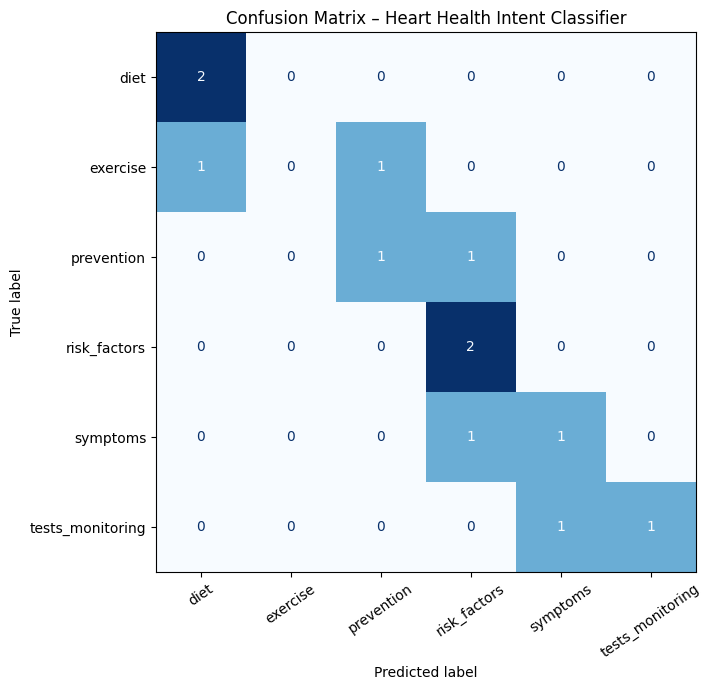

In [8]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)
plt.title("Confusion Matrix – Heart Health Intent Classifier")
plt.tight_layout()
plt.show()

## 8. Domain-specific knowledge base


In [9]:
knowledge_base = {
    "symptoms": (
        "Heart-related symptoms can include chest discomfort, shortness of breath, "
        "palpitations, unusual fatigue, dizziness, or swelling. Symptoms have many "
        "possible causes and cannot be diagnosed by this assistant. Sudden or severe "
        "symptoms need urgent medical assessment."
    ),
    "prevention": (
        "General heart-health habits include avoiding tobacco, being physically active, "
        "choosing balanced meals, getting adequate sleep, and attending recommended "
        "health checkups. A healthcare professional can help tailor advice to an individual."
    ),
    "diet": (
        "A heart-supportive eating pattern commonly emphasizes vegetables, fruits, "
        "whole grains, beans, nuts, and appropriate sources of protein. Limiting excess "
        "salt, highly processed foods, and foods high in saturated or trans fats may be helpful. "
        "Individual dietary needs vary."
    ),
    "exercise": (
        "Regular physical activity supports cardiovascular fitness. Adults are commonly "
        "advised to aim for at least 150 minutes of moderate-intensity aerobic activity "
        "per week, if appropriate for them. Start gradually and ask a healthcare professional "
        "before beginning if you have symptoms or a medical condition."
    ),
    "risk_factors": (
        "Important cardiovascular risk factors include high blood pressure, unhealthy "
        "cholesterol levels, tobacco use, diabetes, physical inactivity, and family history. "
        "Age and other health factors can also matter. A clinician can assess personal risk."
    ),
    "tests_monitoring": (
        "Common heart-health assessments include blood pressure measurement, cholesterol "
        "or lipid tests, and an electrocardiogram (ECG). Other tests may be considered by "
        "a clinician based on symptoms and medical history. This assistant cannot interpret "
        "personal test results."
    )
}

for intent, information in knowledge_base.items():
    print(f"\n{intent.upper()}\n{information}")


SYMPTOMS
Heart-related symptoms can include chest discomfort, shortness of breath, palpitations, unusual fatigue, dizziness, or swelling. Symptoms have many possible causes and cannot be diagnosed by this assistant. Sudden or severe symptoms need urgent medical assessment.

PREVENTION
General heart-health habits include avoiding tobacco, being physically active, choosing balanced meals, getting adequate sleep, and attending recommended health checkups. A healthcare professional can help tailor advice to an individual.

DIET
A heart-supportive eating pattern commonly emphasizes vegetables, fruits, whole grains, beans, nuts, and appropriate sources of protein. Limiting excess salt, highly processed foods, and foods high in saturated or trans fats may be helpful. Individual dietary needs vary.

EXERCISE
Regular physical activity supports cardiovascular fitness. Adults are commonly advised to aim for at least 150 minutes of moderate-intensity aerobic activity per week, if appropriate for 

## 9. Reasoning rules

The assistant applies safety and routing rules before returning knowledge-base information.

Rules implemented:
1. **Emergency escalation:** urgent warning phrases trigger an emergency message before classification.
2. **Low-confidence handling:** uncertain classifier predictions ask the user to rephrase or consult a professional.
3. **Unsupported-query handling:** unrelated or out-of-scope requests are not answered as heart-health advice.
4. **Intent-based retrieval:** supported intents retrieve the matching knowledge-base entry.
5. **No diagnosis or treatment:** the assistant does not diagnose, prescribe, or interpret individual test results.
6. **Professional-care reminder:** personal symptoms or concerns should be discussed with a qualified healthcare professional.

In [10]:
EMERGENCY_PHRASES = [
    "chest pain", "chest pressure", "crushing chest", "severe chest discomfort",
    "shortness of breath", "cannot breathe", "can't breathe", "difficulty breathing",
    "fainting", "passed out", "face drooping", "one side weak",
    "sudden weakness", "severe sweating with chest"
]

HEART_DOMAIN_TERMS = [
    "heart", "cardiac", "cardiovascular", "blood pressure", "cholesterol",
    "ecg", "electrocardiogram", "pulse", "blood vessel", "heart attack",
    "exercise", "smoking", "diabetes", "diet", "salt", "sodium",
    "chest", "palpitation", "circulation", "lipid"
]

def is_emergency(text):
    normalized = text.lower()
    return any(phrase in normalized for phrase in EMERGENCY_PHRASES)

def is_in_domain(text):
    normalized = text.lower()
    return any(term in normalized for term in HEART_DOMAIN_TERMS)

def assistant_response(query, confidence_threshold=0.38):
    # Rule 1: emergency escalation has highest priority
    if is_emergency(query):
        return (
            "EMERGENCY SAFETY ALERT: Your message mentions a possible emergency warning sign. "
            "Call your local emergency number now or seek emergency medical care immediately. "
            "Do not drive yourself if you may be having a medical emergency. Do not wait for "
            "an online response. This assistant cannot assess or rule out an emergency."
        )

    # Rule 2: unsupported queries
    if not is_in_domain(query):
        return (
            "I can only provide general heart-health information in this prototype. "
            "Please ask about heart symptoms, prevention, diet, exercise, risk factors, "
            "or heart-health tests."
        )

    processed = preprocess_text(query)
    if not processed.strip():
        return "I could not understand that query. Please rephrase it using a few more words."

    # Classifier confidence
    probabilities = model.predict_proba([processed])[0]
    best_index = int(np.argmax(probabilities))
    predicted_intent = model.classes_[best_index]
    confidence = float(probabilities[best_index])

    # Rule 3: low confidence
    if confidence < confidence_threshold:
        return (
            f"I'm not confident enough to classify that question (confidence: {confidence:.2f}). "
            "Please rephrase it, or ask a qualified healthcare professional for personal advice."
        )

    # Rule 4 and 5: knowledge retrieval, no diagnosis/prescription
    answer = knowledge_base[predicted_intent]
    return (
        f"Detected intent: {predicted_intent.replace('_', ' ').title()} "
        f"(confidence: {confidence:.2f})\n\n"
        f"{answer}\n\n"
        "Reminder: This is general educational information, not a diagnosis or a treatment plan."
    )

print("Reasoning rules are ready.")

Reasoning rules are ready.


## 10. Test cases required by the assignment

In [11]:
test_queries = [
    ("Query for symptoms intent", "What are common symptoms of heart problems?"),
    ("Query for prevention intent", "How can I prevent heart disease?"),
    ("Query for diet intent", "What foods are good for heart health?"),
    ("Query for exercise intent", "Is walking useful for cardiovascular fitness?"),
    ("Query for risk factors intent", "Does high cholesterol increase heart risk?"),
    ("Query for tests intent", "What does an ECG test measure?"),
    ("Differently worded query", "Ways to look after my ticker through daily habits"),
    ("Unsupported query", "How do I repair a bicycle tyre?"),
    ("Low-confidence / vague query", "Tell me about it"),
    ("Emergency-related query", "I have severe chest pain and difficulty breathing")
]

for title, query in test_queries:
    print("=" * 85)
    print(title)
    print("User:", query)
    print("Assistant:", assistant_response(query))
    print()

Query for symptoms intent
User: What are common symptoms of heart problems?
Assistant: I'm not confident enough to classify that question (confidence: 0.30). Please rephrase it, or ask a qualified healthcare professional for personal advice.

Query for prevention intent
User: How can I prevent heart disease?
Assistant: I'm not confident enough to classify that question (confidence: 0.27). Please rephrase it, or ask a qualified healthcare professional for personal advice.

Query for diet intent
User: What foods are good for heart health?
Assistant: I'm not confident enough to classify that question (confidence: 0.23). Please rephrase it, or ask a qualified healthcare professional for personal advice.

Query for exercise intent
User: Is walking useful for cardiovascular fitness?
Assistant: I'm not confident enough to classify that question (confidence: 0.23). Please rephrase it, or ask a qualified healthcare professional for personal advice.

Query for risk factors intent
User: Does high

## 11. Interactive assistant – enter multiple queries

Run the cell and enter questions one by one. Type `exit` to stop. The assistant will check for emergency phrases, route supported heart-health questions, and handle unsupported or low-confidence inputs.

In [12]:
print("HEART HEALTH INFORMATION ASSISTANT")
print("Ask a general heart-health question. Type 'exit' to stop.\n")

while True:
    user_query = input("You: ").strip()
    if user_query.lower() in {"exit", "quit", "stop"}:
        print("Assistant: Take care. For personal medical advice, consult a qualified healthcare professional.")
        break

    print("\nAssistant:", assistant_response(user_query))
    print()

HEART HEALTH INFORMATION ASSISTANT
Ask a general heart-health question. Type 'exit' to stop.

You: pain in heart

Assistant: I'm not confident enough to classify that question (confidence: 0.23). Please rephrase it, or ask a qualified healthcare professional for personal advice.

You: exit
Assistant: Take care. For personal medical advice, consult a qualified healthcare professional.


## 12. Optional notebook chat interface using ipywidgets


In [13]:
import ipywidgets as widgets
from IPython.display import display, clear_output

query_box = widgets.Text(
    value="",
    placeholder="Ask a heart-health question...",
    description="Question:",
    layout=widgets.Layout(width="80%")
)
ask_button = widgets.Button(description="Ask Assistant", button_style="primary")
chat_output = widgets.Output()

def on_ask_clicked(_):
    query = query_box.value.strip()
    if not query:
        with chat_output:
            print("Please enter a question.")
        return
    with chat_output:
        print("You:", query)
        print("Assistant:", assistant_response(query))
        print("-" * 70)
    query_box.value = ""

ask_button.on_click(on_ask_clicked)
display(widgets.VBox([query_box, ask_button, chat_output]))